# Tema 19 · Entrenar bien: optimizadores, inicialización y regularización

Las decisiones que separan una red que aprende de una que no.

Este cuaderno es el tema 19 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/19-entrenar-bien-optimizadores-inicializacion-y-regularizacion/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

# Teoría

## La pregunta

Dos estudiantes copian la misma red neuronal, con las mismas imágenes de ropa, y la entrenan el mismo rato. A una le llega a más de 80 % de aciertos; al otro se le queda clavada en 10 %, que es lo que saca alguien que adivina al azar entre diez clases. El código es casi idéntico: cambian unas pocas líneas. ¿Cuáles?

Casi siempre la respuesta está en alguna de estas decisiones: **qué optimizador** baja por la pérdida, **qué tasa de aprendizaje** usa, **con cuántos ejemplos** calcula cada paso, **cómo empiezan los pesos** y **qué se hace para que la red no memorice**. Ninguna cambia la arquitectura de la red, y todas pueden separar una red que aprende de una que no.

En este tema vas a:

- comparar el descenso de gradiente **completo**, el **estocástico** y el de **mini-lotes**;
- elegir entre **SGD con momentum**, **Adam** y **AdamW**, encontrar una tasa de aprendizaje razonable con un **buscador de tasa** y cambiarla durante el entrenamiento con un **programador**;
- explicar para qué sirven la **inicialización** (Xavier y He) y la **normalización por lotes**;
- combatir el sobreajuste con **dropout**, **decaimiento de pesos** y **parada temprana**;
- **diagnosticar** un entrenamiento mirando sus curvas.

Es un tema largo. Las partes marcadas como «Para profundizar (opcional)» puedes dejarlas para una segunda lectura: el resto del tema y los ejercicios principales no las necesitan.

Necesitas el descenso de gradiente y la tasa de aprendizaje del tema 6, el sobreajuste y la regularización del tema 7, y el bucle de entrenamiento de PyTorch del tema 18.

## Actividad: carrera de optimizadores

En el tema 6 bajaste un valle con una sola bola. Ahora son tres, que parten del mismo lugar y bajan por el mismo paisaje, cada una con su regla para dar el paso:

- **SGD** (el cuadrado) es el descenso de gradiente de siempre: un paso en contra de la pendiente, del largo que marca la tasa.
- **Momentum** (el triángulo) recuerda hacia dónde venía: acumula velocidad, como una bola pesada.
- **Adam** (la bola coral) ajusta el largo del paso en cada dirección por separado.

El paisaje de partida es un **valle estrecho y curvado**: las paredes son muy empinadas y el fondo baja muy suave hasta el mínimo, marcado con una cruz. Toca el mapa para cambiar el punto de partida.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/19-entrenar-bien-optimizadores-inicializacion-y-regularizacion/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Pulsa «Correr» con los valores iniciales. ¿Quién llega primero a la cruz? ¿Dónde se queda SGD?
2. Reinicia y sube la tasa de SGD hasta que empiece a zigzaguear entre las paredes. Súbela un poco más: ¿qué pasa?
3. Vuelve a la tasa inicial y baja el *β* del momentum a 0. ¿En qué se convierte el triángulo? Súbelo a 0,99.
4. Cambia al paisaje **cuenco**. ¿Sigue importando tanto qué optimizador uses?
5. Cambia a **varios mínimos**. ¿Todas las bolas terminan en el mismo hoyo? ¿Cuál es el más hondo?

La idea que te llevas: **el momentum cruza los valles estrechos porque acumula velocidad en la dirección del fondo, una tasa alta hace oscilar entre las paredes y Adam se adapta dando pasos de largo parecido en cada coordenada**. El resto del tema pone esto en código y lo prueba en una red de verdad.

## El banco de pruebas

Vamos a hacer muchos experimentos cortos con **FashionMNIST**, las fotos de prendas del tema 18. Para que cada experimento tarde segundos y no minutos, usamos una **submuestra**: 6000 imágenes para entrenar y 2000 para validar, todas tomadas del conjunto de entrenamiento original. El conjunto de prueba no lo tocamos: se usa una sola vez, al final de un proyecto (tema 7). Con los datos completos y más épocas, todos los números de este tema subirían; lo que nos interesa aquí es **comparar** decisiones con las mismas condiciones.

Como las imágenes son pocas, en lugar de pasar por las transformaciones de torchvision ponemos todas en un solo tensor de una vez y armamos los cargadores con `TensorDataset`.

In [ ]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

fashion = datasets.FashionMNIST(root="datos", train=True, download=True)
# Mezclamos una vez, con semilla, y tomamos una submuestra
orden = torch.randperm(len(fashion),
                       generator=torch.Generator().manual_seed(0))
X = fashion.data[orden].float() / 255     # píxeles entre 0 y 1
y = fashion.targets[orden]
X_ent, y_ent = X[:6000], y[:6000]
X_val, y_val = X[6000:8000], y[6000:8000]
print("Entrenamiento:", tuple(X_ent.shape),
      "  Validación:", tuple(X_val.shape))


def cargadores(lote=64, X_e=X_ent, y_e=y_ent):
    """Cargadores nuevos, con la misma mezcla en cada experimento."""
    mezcla = torch.Generator().manual_seed(0)
    ent = DataLoader(TensorDataset(X_e, y_e), batch_size=lote,
                     shuffle=True, generator=mezcla)
    val = DataLoader(TensorDataset(X_val, y_val), batch_size=1000)
    return ent, val


def mlp():
    """Un MLP como el del tema 18, pero más ancho: 784 → 256 → 10."""
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                         nn.Linear(256, 10))

Entrenamiento: (6000, 28, 28)   Validación: (2000, 28, 28)


`cargadores` crea cargadores nuevos con la misma semilla, y antes de cada experimento fijamos `torch.manual_seed(0)`: así todas las redes de una comparación empiezan con los mismos pesos y ven los lotes en el mismo orden. Si algo cambia, es por la decisión que estamos probando.

Y esta es la función `entrenar` del tema 18, tal cual (con su compañera `evaluar`). Cópiala en tu cuaderno; no la volvemos a explicar. Devuelve un historial con la pérdida y la exactitud de cada época, y acepta un optimizador y un programador de tasa, que son justo lo que vamos a cambiar.

In [ ]:
import torch
from torch import nn


def evaluar(modelo, cargador, funcion_perdida, dispositivo="cpu"):
    """Pérdida media y exactitud de `modelo` sobre `cargador`."""
    modelo.eval()
    suma, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            suma += funcion_perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
    return suma / total, aciertos / total


def entrenar(modelo, cargador_ent, cargador_val, epocas, optimizador,
             funcion_perdida=None, planificador=None, dispositivo="cpu",
             mostrar=True):
    """Entrena `modelo` y devuelve el historial de cada época."""
    if funcion_perdida is None:
        funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(dispositivo)
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, aciertos, total = 0.0, 0, 0
        for x, y in cargador_ent:
            x, y = x.to(dispositivo), y.to(dispositivo)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
        if planificador is not None:
            planificador.step()
        perdida_val, exactitud_val = evaluar(
            modelo, cargador_val, funcion_perdida, dispositivo)
        historial["perdida_ent"].append(suma / total)
        historial["exactitud_ent"].append(aciertos / total)
        historial["perdida_val"].append(perdida_val)
        historial["exactitud_val"].append(exactitud_val)
        if mostrar:
            print(f"Época {epoca}: pérdida {suma / total:.3f}, "
                  f"validación {perdida_val:.3f}, "
                  f"exactitud de validación {exactitud_val:.3f}")
    return historial

## Completo, estocástico o por mini-lotes

En el tema 6, cada paso del descenso usaba **todos** los ejemplos para calcular el gradiente. Eso se llama descenso de gradiente **completo** (*full batch*). Con 30 estudiantes está bien; con 60 000 fotos, cada paso cuesta recorrer las 60 000.

El otro extremo es usar **un solo ejemplo** por paso: el descenso de gradiente **estocástico** (SGD, por *stochastic gradient descent*). Cada paso es baratísimo, pero el gradiente de un solo ejemplo es una estimación muy ruidosa del gradiente verdadero: una foto de una sandalia empuja los pesos hacia un lado, la siguiente, de un abrigo, hacia otro.

Lo que se usa en la práctica está en el medio: **mini-lotes** de 32 a 256 ejemplos. El gradiente promedio de un lote ya apunta bastante bien, y la computadora procesa el lote entero de una vez con operaciones de matrices. Es lo que hace el `DataLoader` con `batch_size`. (Por costumbre, PyTorch llama `SGD` a su optimizador aunque trabaje con mini-lotes.)

Comparemos los tres con la misma red y la misma tasa, mirando la pérdida de cada lote en los primeros 200 pasos:

Lote de    1: pérdida media de los últimos 20 pasos 1.75
Lote de   64: pérdida media de los últimos 20 pasos 0.77
Lote de 6000: pérdida media de los últimos 20 pasos 0.73


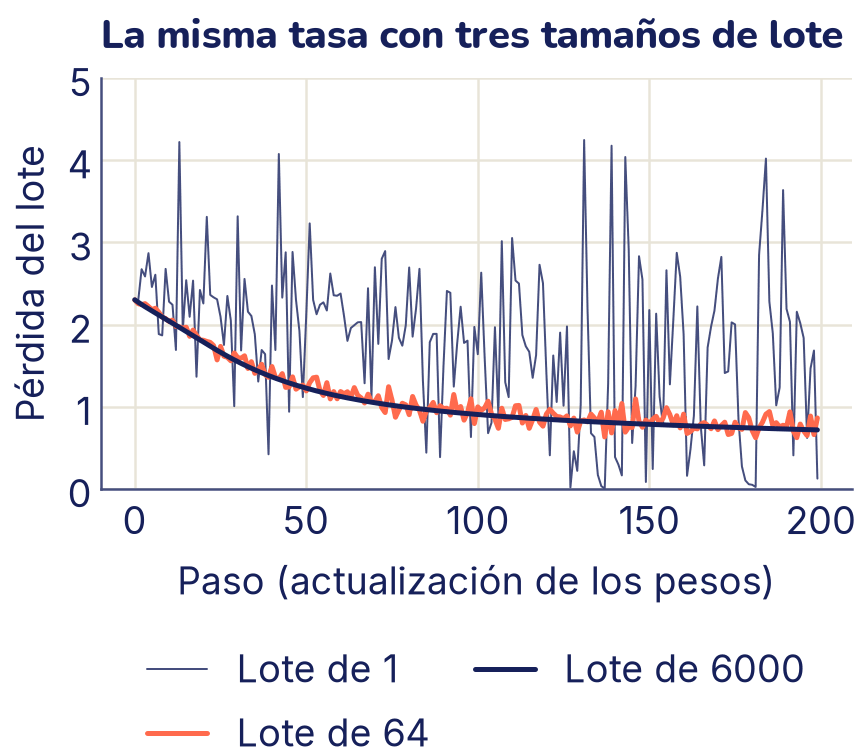

In [ ]:
def perdidas_por_paso(lote, pasos=200, tasa=0.05):
    """La pérdida de cada lote durante los primeros `pasos` pasos."""
    torch.manual_seed(0)
    modelo = mlp()
    optimizador = torch.optim.SGD(modelo.parameters(), lr=tasa)
    funcion_perdida = nn.CrossEntropyLoss()
    cargador_ent, _ = cargadores(lote)
    perdidas = []
    while len(perdidas) < pasos:
        for x, y_lote in cargador_ent:
            optimizador.zero_grad()
            perdida = funcion_perdida(modelo(x), y_lote)
            perdida.backward()
            optimizador.step()
            perdidas.append(perdida.item())
            if len(perdidas) == pasos:
                break
    return perdidas

# Una figura más alta, para dejar lugar a la leyenda debajo
plt.figure(figsize=(4.8, 4.2))
lotes = [(1, "C2", "Lote de 1"), (64, "C1", "Lote de 64"),
         (6000, "C0", "Lote de 6000")]
for lote, color, nombre in lotes:
    perdidas = perdidas_por_paso(lote)
    plt.plot(perdidas, color=color, label=nombre,
             linewidth=0.8 if lote == 1 else 2)
    print(f"Lote de {lote:4d}: pérdida media de los últimos 20 pasos "
          f"{np.mean(perdidas[-20:]):.2f}")
plt.ylim(0, 5)
plt.xlabel("Paso (actualización de los pesos)")
plt.ylabel("Pérdida del lote")
plt.title("La misma tasa con tres tamaños de lote")
# Leyenda debajo del gráfico, para que no tape los saltos del lote de 1
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2,
           frameon=False, handlelength=1.6, columnspacing=1.2)
plt.show()

Paso por paso, los lotes grandes ganan. Con 64 o con 6000 imágenes la pérdida baja casi igual y de forma pareja. Con una sola imagen salta sin parar, porque cada imagen es fácil o difícil por su cuenta, y tras 200 pasos va bastante peor: 1,75 de pérdida media en los últimos 20 pasos, contra 0,77 y 0,73. Fíjate también en que el lote de 64 hace casi lo mismo que el de 6000: un mini-lote ya estima bastante bien el gradiente.

Pero contar pasos no es justo: un paso con 6000 imágenes cuesta unas 6000 veces más cuentas que un paso con una. La comparación honesta es con el mismo trabajo, por ejemplo **una época**: cada red ve las 6000 imágenes una vez.

In [ ]:
for lote in [1, 8, 64, 512, 6000]:
    torch.manual_seed(0)
    modelo = mlp()
    cargador_ent, cargador_val = cargadores(lote)
    optimizador = torch.optim.SGD(modelo.parameters(), lr=0.05)
    h = entrenar(modelo, cargador_ent, cargador_val, 1, optimizador,
                 dispositivo=device, mostrar=False)
    print(f"Lote {lote:4d}: {len(cargador_ent):4d} pasos en la época, "
          f"exactitud de validación {h['exactitud_val'][0]:.3f}")

Lote    1: 6000 pasos en la época, exactitud de validación 0.513
Lote    8:  750 pasos en la época, exactitud de validación 0.735
Lote   64:   94 pasos en la época, exactitud de validación 0.673
Lote  512:   12 pasos en la época, exactitud de validación 0.592
Lote 6000:    1 pasos en la época, exactitud de validación 0.135


Con el mismo trabajo, la historia cambia. El descenso completo da **un solo paso** en toda la época y queda casi como empezó: 13,5 %, apenas mejor que adivinar entre diez clases. Los lotes chicos dan muchos pasos y llegan más lejos, hasta que el ruido les gana: con lotes de 1 la exactitud (51,3 %) es peor que con lotes de 8 (73,5 %).

Lo que esta tabla no muestra es el **tiempo**. La computadora procesa 64 imágenes juntas casi tan rápido como una sola, porque lo hace con operaciones de matrices (y en una GPU la diferencia es todavía mayor). Por eso, en la práctica, se usan lotes de 32 a 256: gradientes bastante estables, buen uso del hardware y muchos pasos por época. El tamaño del lote y la tasa de aprendizaje están relacionados; lo vas a explorar en los ejercicios.

## Momentum: una bola con inercia

Vuelve a la actividad, al valle estrecho. SGD avanza muy despacio: en las paredes empinadas el gradiente es grande y apunta casi de lado, hacia el centro del valle, mientras que a lo largo del fondo, que es hacia donde hay que ir, la pendiente es muy chica. Si subes la tasa para avanzar más rápido por el fondo, los pasos de lado crecen también y la bola rebota de pared a pared.

El **momentum** (en español, *inercia*; usaremos el nombre en inglés, que es el habitual) arregla esto con una idea de la física: una bola pesada no cambia de dirección de golpe. Guardamos una **velocidad** *v*, que es una suma de los gradientes anteriores en la que los más viejos pesan cada vez menos:

$$v \leftarrow \beta \cdot v + g \qquad w \leftarrow w - \alpha \cdot v$$

Aquí *g* es el gradiente del paso actual, *α* la tasa de aprendizaje de siempre y *β* (beta), un número entre 0 y 1, dice cuánto se recuerda: con *β* = 0 es SGD normal; el valor típico es 0,9. Es la forma en que lo escribe PyTorch.

¿Por qué funciona? En el valle estrecho, los empujones de lado cambian de signo en cada paso (izquierda, derecha, izquierda) y en la suma se **cancelan**. Los empujones a lo largo del fondo apuntan siempre hacia el mismo lado y se **acumulan**: si el gradiente se mantiene parecido, la velocidad crece hasta unas 1 / (1 − *β*) veces el gradiente, diez veces con *β* = 0,9. El resultado: menos zigzag y más avance.

En PyTorch es un argumento más de `SGD`:

In [ ]:
optimizador = torch.optim.SGD(mlp().parameters(), lr=0.05, momentum=0.9)

## Adam: un paso a la medida de cada peso

Momentum resuelve el zigzag, pero sigue usando la misma tasa para todos los pesos. En una red hay pesos con gradientes enormes y otros con gradientes diminutos, y una sola tasa no les sirve a todos: o los primeros saltan demasiado, o los segundos casi no se mueven.

**Adam** (de *adaptive moment estimation*) lleva, para cada peso, dos promedios que se van actualizando:

- *m*, el promedio de los gradientes recientes: hacia dónde viene empujando el gradiente. Es la misma idea que el momentum, pero escrita como promedio: por eso aparece (1 − *β*<sub>1</sub>), que deja a *m* en la escala del gradiente en lugar de unas diez veces más grande, como la *v* del momentum;
- *s*, el promedio de los **cuadrados** de los gradientes recientes: qué tan grandes suelen ser.

Y da el paso dividiendo uno por la raíz del otro:

$$m \leftarrow {\beta}_{1} m + ( 1 - {\beta}_{1} ) g \qquad s \leftarrow {\beta}_{2} s + ( 1 - {\beta}_{2} ) {g}^{2} \qquad w \leftarrow w - \alpha \cdot \frac{m}{\sqrt{s} + \varepsilon}$$

Los valores por defecto son *β*<sub>1</sub> = 0,9 y *β*<sub>2</sub> = 0,999; *ε* es un número diminuto que evita dividir por cero. (Adam además corrige *m* y *s* en los primeros pasos, porque empiezan en cero y al principio salen demasiado chicos; en el ejercicio 2 vas a calcular qué efecto tiene.)

La división es la clave. Si un peso tiene gradientes grandes, *m* y √*s* son grandes los dos y el cociente queda cerca de 1 o −1. Si tiene gradientes chicos, los dos son chicos y el cociente también queda cerca de 1 o −1. Así, **cada peso avanza más o menos *α* por paso**, sea cual sea el tamaño de su gradiente. Por eso en la actividad la tasa de Adam va en otra escala que la de SGD: para Adam, *α* es casi directamente el largo del paso; para SGD, es un número que se multiplica por el gradiente. Si un peso recibe gradientes que cambian de signo todo el tiempo, *m* se cancela pero *s* no, y el paso se achica: Adam frena solo en las direcciones donde oscila.

Veamos la carrera con código. La función de **Rosenbrock** es un valle estrecho y curvado clásico para probar optimizadores, con el mínimo en (1, 1). Es el paisaje de la actividad. PyTorch puede bajar por cualquier función que se pueda derivar, no solo por la pérdida de una red: basta con que los parámetros sean un tensor con `requires_grad=True`.

In [ ]:
def rosenbrock(p):
    """Un valle estrecho y curvado con el mínimo en (1, 1)."""
    x, y = p
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2


def recorrido(crear_optimizador, pasos=500):
    """Baja por Rosenbrock desde (-1.2, 1) y devuelve el camino."""
    p = torch.tensor([-1.2, 1.0], requires_grad=True)
    optimizador = crear_optimizador([p])
    camino = [p.detach().clone()]
    for _ in range(pasos):
        optimizador.zero_grad()
        rosenbrock(p).backward()
        optimizador.step()
        camino.append(p.detach().clone())
    return torch.stack(camino)


caminos = {
    "SGD": recorrido(lambda q: torch.optim.SGD(q, lr=0.001)),
    "Momentum": recorrido(
        lambda q: torch.optim.SGD(q, lr=0.001, momentum=0.9)),
    "Adam": recorrido(lambda q: torch.optim.Adam(q, lr=0.1)),
}
for nombre, camino in caminos.items():
    x, y_ = camino[-1].tolist()
    altura = rosenbrock(camino[-1]).item()
    print(f"{nombre:8s} termina en ({x:5.2f}, {y_:5.2f}), "
          f"altura {altura:.4f}")

SGD      termina en (-0.51,  0.27), altura 2.2849
Momentum termina en ( 0.96,  0.92), altura 0.0018
Adam     termina en ( 0.88,  0.77), altura 0.0155


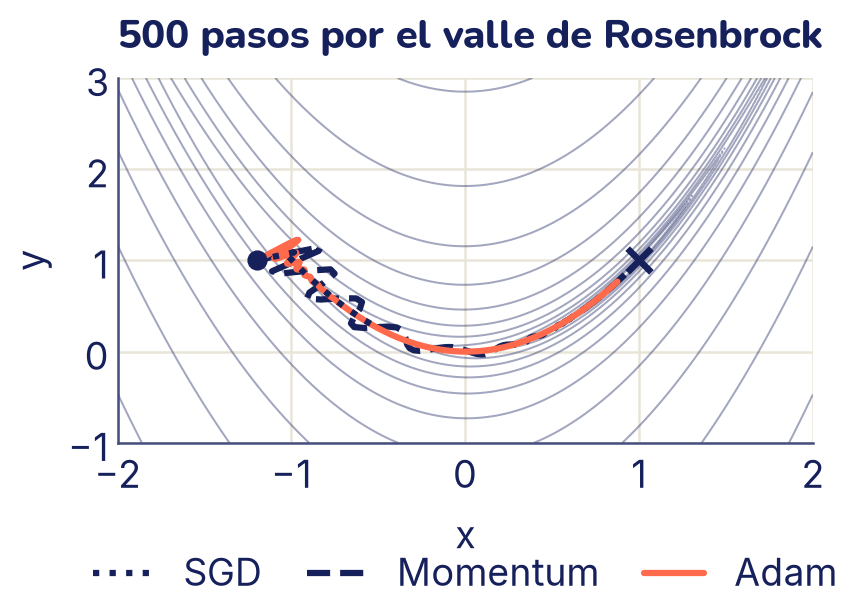

In [ ]:
# El mapa: la altura en una cuadrícula, en curvas de nivel
xs = np.linspace(-2, 2, 300)
ys = np.linspace(-1, 3, 300)
XX, YY = np.meshgrid(xs, ys)
ZZ = (1 - XX) ** 2 + 100 * (YY - XX ** 2) ** 2
plt.contour(XX, YY, ZZ, levels=np.geomspace(0.1, 2000, 12),
            colors="C2", linewidths=0.8, alpha=0.5)

estilos = {"SGD": ("C0", ":"), "Momentum": ("C0", "--"),
           "Adam": ("C1", "-")}
for nombre, camino in caminos.items():
    color, linea = estilos[nombre]
    # SGD encima: su camino es corto y quedaría tapado
    plt.plot(camino[:, 0], camino[:, 1], color=color, linestyle=linea,
             linewidth=2.5, label=nombre, zorder=3 if nombre == "SGD" else 2)
plt.scatter([-1.2], [1], color="C0", s=50, zorder=3)
plt.scatter([1], [1], color="C0", marker="x", s=90, zorder=3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("500 pasos por el valle de Rosenbrock")
# La leyenda va debajo del gráfico, para no tapar las curvas
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3,
           frameon=False, handlelength=1.6, columnspacing=1.2)
plt.show()

En 500 pasos, SGD avanzó muy poco por el fondo: terminó en (−0,51; 0,27), a altura 2,28. Con la misma tasa, momentum llegó casi al mínimo (altura 0,0018), y Adam también se acercó mucho (0,0155). Ojo con sacar conclusiones generales de una sola carrera: con otras tasas o desde otro punto el orden puede cambiar, como habrás visto en la actividad. Lo que sí es general es el motivo: SGD sufre en los valles estrechos, y momentum y Adam están hechos para ellos.

### AdamW

**AdamW** es Adam con una corrección en cómo se aplica el **decaimiento de pesos** (*weight decay*), una regularización que encoge los pesos en cada paso. La vas a ver en la sección de regularización; por ahora, basta saber que hoy es el optimizador por defecto de muchísimos proyectos.

### En una red de verdad

Ahora los cuatro con la misma red en FashionMNIST, diez épocas cada uno. Las tasas son las habituales para cada optimizador: 0,05 para SGD y 0,001 para Adam y AdamW (el valor por defecto de PyTorch).

In [ ]:
optimizadores = {
    "SGD": lambda p: torch.optim.SGD(p, lr=0.05),
    "SGD+momentum": lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "Adam": lambda p: torch.optim.Adam(p, lr=0.001),
    "AdamW": lambda p: torch.optim.AdamW(p, lr=0.001, weight_decay=0.01),
}
for nombre, crear in optimizadores.items():
    torch.manual_seed(0)          # la misma red inicial para todos
    modelo = mlp()
    cargador_ent, cargador_val = cargadores()
    h = entrenar(modelo, cargador_ent, cargador_val, 10,
                 crear(modelo.parameters()), dispositivo=device,
                 mostrar=False)
    print(f"{nombre:13s} exactitud de validación: "
          f"época 1 = {h['exactitud_val'][0]:.3f}, "
          f"época 10 = {h['exactitud_val'][-1]:.3f}")

SGD           exactitud de validación: época 1 = 0.673, época 10 = 0.807
SGD+momentum  exactitud de validación: época 1 = 0.788, época 10 = 0.820
Adam          exactitud de validación: época 1 = 0.759, época 10 = 0.822
AdamW         exactitud de validación: época 1 = 0.759, época 10 = 0.823


Después de una época, momentum y Adam ya van muy por delante de SGD (78,8 % y 75,9 %, contra 67,3 %). Después de diez, los cuatro quedan entre 80,7 % y 82,3 %: SGD sin momentum sigue último y los otros tres quedan casi empatados. Con esta red y estos datos, la gran diferencia está al principio: los optimizadores con momentum llegan antes.

¿Cuál elegir? Una regla práctica razonable:

- **Adam o AdamW con tasa 0,001** es el punto de partida más seguro: funciona bien sin mucho ajuste. Si vas a usar decaimiento de pesos, usa AdamW.
- **SGD con momentum 0,9** necesita buscar mejor la tasa, pero bien ajustado (y con un programador de tasa) a veces generaliza un poco mejor; se usa mucho en visión.
- **SGD sin momentum** casi nunca es la mejor opción en una red.

## Elegir la tasa de aprendizaje

**Para profundizar (opcional).** Esta sección y la siguiente (el buscador de tasa y los programadores) no hacen falta para seguir el tema: con Adam y tasa 0,001 se llega lejos. Solo el paso 5 del mini-proyecto las usa.

Del tema 6 sabes que la tasa es la decisión más importante: muy chica, la red apenas aprende; muy grande, diverge. Con una recta podíamos probar tasas a mano. Con una red, cada prueba es un entrenamiento entero. Un **buscador de tasa** lo resuelve en una sola pasada corta:

1. Empieza con una tasa diminuta, por ejemplo 0,00001.
2. Después de cada lote, multiplica la tasa por un factor fijo, de modo que en unos cien lotes llegue a 10.
3. Anota la pérdida de cada lote y para cuando la pérdida se dispara.

Con tasas diminutas la pérdida casi no cambia; en algún momento empieza a bajar rápido; con tasas grandes, explota. Se elige una tasa **antes** del punto más bajo de la curva, donde la pérdida todavía baja con fuerza: una regla común es tomar unas diez veces menos que la tasa del mínimo.

La pérdida más baja fue con tasa 0.091
Tasa elegida (diez veces menos): 0.0091


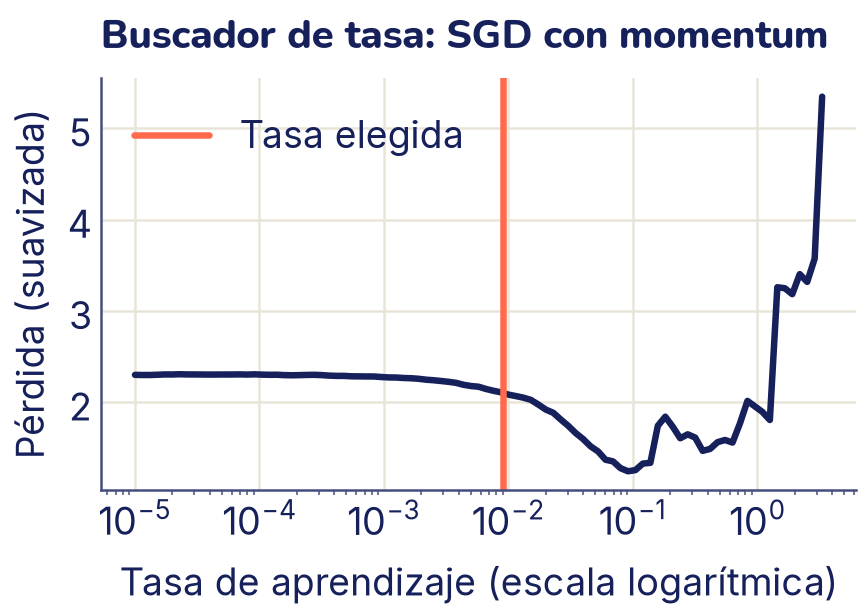

In [ ]:
def buscar_tasa(modelo, crear_optimizador, cargador_ent,
                tasa_min=1e-5, tasa_max=10, pasos=100):
    """Sube la tasa en cada lote y anota la pérdida (suavizada)."""
    optimizador = crear_optimizador(modelo.parameters(), tasa_min)
    funcion_perdida = nn.CrossEntropyLoss()
    factor = (tasa_max / tasa_min) ** (1 / pasos)
    # float("inf") es infinito: cualquier pérdida real será menor
    tasa, suave, mejor = tasa_min, None, float("inf")
    tasas, perdidas = [], []
    modelo.train()
    for x, y_lote in cargador_ent:
        # param_groups guarda los ajustes del optimizador, como "lr"
        for grupo in optimizador.param_groups:
            grupo["lr"] = tasa        # la tasa nueva para este paso
        optimizador.zero_grad()
        perdida = funcion_perdida(modelo(x), y_lote)
        perdida.backward()
        optimizador.step()
        # Promedio móvil: la pérdida de un lote sola es muy ruidosa
        p = perdida.item()
        suave = p if suave is None else 0.8 * suave + 0.2 * p
        tasas.append(tasa)
        perdidas.append(suave)
        mejor = min(mejor, suave)
        if suave > 4 * mejor or len(tasas) == pasos:
            break                     # la pérdida se disparó
        tasa *= factor
    return np.array(tasas), np.array(perdidas)


torch.manual_seed(0)
cargador_ent, cargador_val = cargadores()
tasas, perdidas = buscar_tasa(
    mlp(), lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    cargador_ent)
tasa_del_minimo = tasas[np.argmin(perdidas)]
tasa_elegida = tasa_del_minimo / 10
print(f"La pérdida más baja fue con tasa {tasa_del_minimo:.3f}")
print(f"Tasa elegida (diez veces menos): {tasa_elegida:.4f}")

plt.plot(tasas, perdidas, color="C0")
plt.axvline(tasa_elegida, color="C1", label="Tasa elegida")
plt.xscale("log")
plt.xlabel("Tasa de aprendizaje (escala logarítmica)")
plt.ylabel("Pérdida (suavizada)")
plt.title("Buscador de tasa: SGD con momentum")
plt.legend()
plt.show()

La curva tiene las tres zonas: plana mientras la tasa es diminuta (los pasos casi no mueven los pesos), en bajada entre 0,001 y 0,1, y en explosión pasando de 1. El punto más bajo está en 0,091, y la regla de dividir por diez da 0,0091.

El buscador no da una respuesta exacta: da una **zona razonable** en una pasada de un minuto. Para elegir entre dos o tres tasas de esa zona, se entrena con cada una y se compara la pérdida de validación.

### Cambiar la tasa durante el entrenamiento

**Para profundizar (opcional).** Al principio del entrenamiento conviene dar pasos largos, para avanzar rápido. Al final, cerca del fondo, los pasos largos hacen rebotar la bola de un lado al otro (lo viste en la actividad) y conviene acortarlos. Un **programador de tasa** (*learning rate scheduler*) cambia la tasa época a época. Los tres más comunes:

- **`StepLR`**: multiplica la tasa por un factor (por ejemplo 0,5) cada cierto número de épocas. Una escalera.
- **`CosineAnnealingLR`**: baja la tasa suavemente, siguiendo medio coseno, desde la tasa inicial hasta casi cero en la última época.
- **Calentamiento** (*warmup*): las primeras épocas la tasa **sube** desde un valor chico. Los pesos recién inicializados pueden dar gradientes muy grandes, y empezar suave evita un primer salto que arruine el entrenamiento. Se combina con otro programador para el resto.

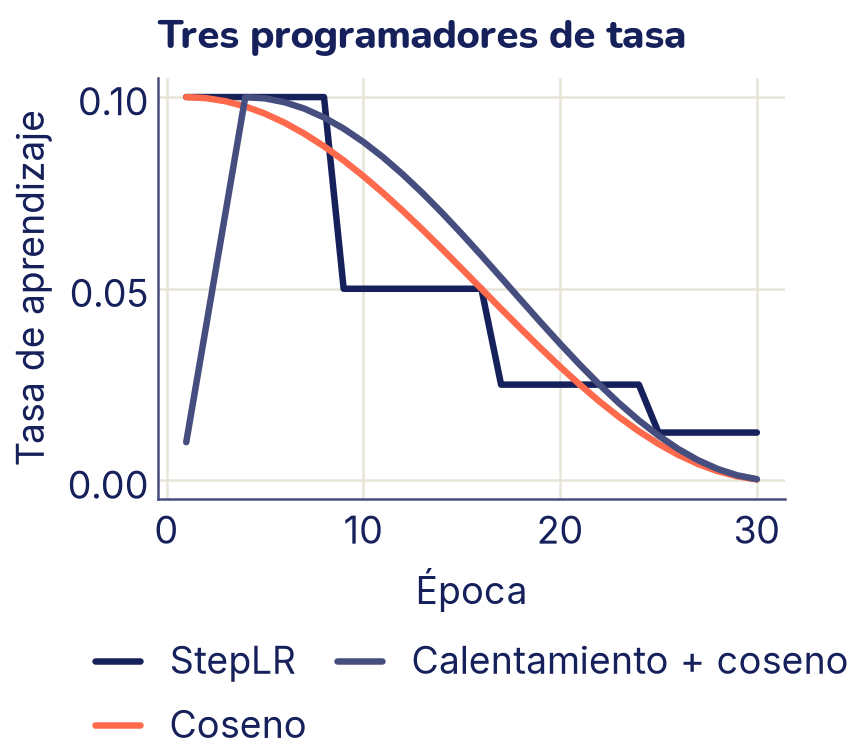

In [ ]:
def tasas_por_epoca(crear_programador, epocas=30, tasa=0.1):
    """Aplica el programador a un optimizador de prueba y anota."""
    peso = torch.zeros(1, requires_grad=True)
    optimizador = torch.optim.SGD([peso], lr=tasa)
    programador = crear_programador(optimizador)
    tasas = []
    for _ in range(epocas):
        tasas.append(optimizador.param_groups[0]["lr"])
        optimizador.step()        # en un entrenamiento real, una época
        programador.step()
    return tasas

lr_scheduler = torch.optim.lr_scheduler
programadores = {
    "StepLR": (lambda o: lr_scheduler.StepLR(o, step_size=8, gamma=0.5),
               "C0"),
    "Coseno": (lambda o: lr_scheduler.CosineAnnealingLR(o, T_max=30),
               "C1"),
    "Calentamiento + coseno": (lambda o: lr_scheduler.SequentialLR(
        o, [lr_scheduler.LinearLR(o, start_factor=0.1, total_iters=3),
            lr_scheduler.CosineAnnealingLR(o, T_max=27)],
        milestones=[3]), "C2"),
}
# Una figura más alta, para dejar lugar a la leyenda debajo
plt.figure(figsize=(4.8, 4.2))
for nombre, (crear, color) in programadores.items():
    plt.plot(range(1, 31), tasas_por_epoca(crear), color=color,
             label=nombre)
plt.xlabel("Época")
plt.ylabel("Tasa de aprendizaje")
plt.title("Tres programadores de tasa")
# Marcas cortas en el eje y la leyenda debajo, sin tapar las curvas
plt.yticks([0, 0.05, 0.1])
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2,
           frameon=False, handlelength=1.2, columnspacing=0.8)
plt.show()

Con la función `entrenar`, el programador se pasa como `planificador` y ella llama a su `step()` al final de cada época. Probemos dos tasas de la zona que marcó el buscador (diez y tres veces menos que la del mínimo), cada una con tasa fija y con coseno, diez épocas:

In [ ]:
for tasa in [tasa_del_minimo / 10, tasa_del_minimo / 3]:
    for usar_coseno in [False, True]:
        torch.manual_seed(0)
        modelo = mlp()
        cargador_ent, cargador_val = cargadores()
        optimizador = torch.optim.SGD(modelo.parameters(), lr=tasa,
                                      momentum=0.9)
        programador = None
        if usar_coseno:
            programador = lr_scheduler.CosineAnnealingLR(optimizador,
                                                         T_max=10)
        h = entrenar(modelo, cargador_ent, cargador_val, 10, optimizador,
                     planificador=programador, dispositivo=device,
                     mostrar=False)
        nombre = "con coseno" if usar_coseno else "tasa fija "
        print(f"Tasa {tasa:.3f} {nombre}: pérdida de validación "
              f"{h['perdida_val'][-1]:.3f}, "
              f"exactitud {h['exactitud_val'][-1]:.3f}")

Tasa 0.009 tasa fija : pérdida de validación 0.538, exactitud 0.816
Tasa 0.009 con coseno: pérdida de validación 0.546, exactitud 0.811
Tasa 0.030 tasa fija : pérdida de validación 0.571, exactitud 0.809
Tasa 0.030 con coseno: pérdida de validación 0.471, exactitud 0.833


Con la tasa más chica, el coseno casi no cambia nada: con 0,009 los pasos ya eran cortos. Con 0,030 la historia es otra. Con tasa fija termina peor que con la chica (pérdida de validación 0,571): los pasos largos la hacen rebotar cerca del fondo. Con coseno, esa misma tasa da el mejor resultado de los cuatro, con pérdida 0,471 y exactitud de 83,3 %: pasos largos al principio para avanzar rápido y cortos al final para asentarse. Es una combinación muy usada: una tasa algo alta, sacada del buscador, y un programador que la va bajando.

## La inicialización: cómo empiezan los pesos

Antes del primer paso, los pesos necesitan algún valor. Parece un detalle, pero decide si la red puede aprender.

**No pueden empezar todos iguales.** Si todas las neuronas de una capa tienen los mismos pesos, calculan lo mismo, reciben el mismo gradiente y cambian igual: siguen siendo copias unas de otras para siempre. Una capa de 256 neuronas idénticas vale lo mismo que una sola neurona. Esto se llama el problema de la **simetría**, y por eso los pesos se inicializan **al azar**. Comprobémoslo poniendo todos los pesos en 0,01:

In [ ]:
torch.manual_seed(0)
red = mlp()
for capa in [red[1], red[3]]:     # las dos capas lineales
    nn.init.constant_(capa.weight, 0.01)
    nn.init.zeros_(capa.bias)
cargador_ent, cargador_val = cargadores()
optimizador = torch.optim.SGD(red.parameters(), lr=0.05, momentum=0.9)
h = entrenar(red, cargador_ent, cargador_val, 3, optimizador,
             dispositivo=device, mostrar=False)

pesos_ocultos = red[1].weight.detach()      # una fila por neurona
diferencia = (pesos_ocultos - pesos_ocultos[0]).abs().max().item()
print(f"Las 256 neuronas ocultas, tras 3 épocas: diferencia máxima "
      f"entre ellas = {diferencia:.1f}")
print(f"Exactitud de validación: {h['exactitud_val'][-1]:.3f}")

Las 256 neuronas ocultas, tras 3 épocas: diferencia máxima entre ellas = 0.0
Exactitud de validación: 0.112


Después de tres épocas, las 256 neuronas ocultas siguen teniendo exactamente los mismos pesos, y la red acierta 11,2 %, casi como adivinar. Con pesos al azar, esta misma red con el mismo optimizador pasaba de 78 % en la primera época (la tabla de los optimizadores).

**Tampoco da igual cuán grandes sean.** Cada capa suma muchas entradas multiplicadas por pesos. Si los pesos son muy chicos, la suma se achica en cada capa, y después de varias capas las señales son casi cero (y los gradientes también: la red no aprende). Si son muy grandes, la suma crece en cada capa; con tanh o sigmoide las neuronas se **saturan** (quedan pegadas en −1 o 1, donde la derivada es casi cero) y con ReLU los valores explotan.

¿Qué escala es la justa? Una neurona suma *n* entradas, cada una multiplicada por un peso al azar con desviación *σ*. Al sumar cosas al azar independientes, sus varianzas se suman: si las entradas tienen desviación 1, la suma tiene varianza *n*·*σ*², y desviación √*n*·*σ*. Para que la señal no crezca ni se achique, hace falta *n*·*σ*² ≈ 1, es decir, *σ* ≈ 1/√*n*. Comprobémoslo con 256 entradas:

In [ ]:
torch.manual_seed(0)
entradas = torch.randn(10000, 256)       # 10 000 ejemplos, desviación 1
for sigma in [0.01, 1.0, 1 / 256 ** 0.5]:
    w = torch.randn(256) * sigma         # pesos de una neurona
    suma = entradas @ w
    print(f"σ = {sigma:.4f}: desviación de la suma {suma.std():.2f}")

σ = 0.0100: desviación de la suma 0.15
σ = 1.0000: desviación de la suma 15.75
σ = 0.0625: desviación de la suma 0.98


Con *σ* = 0,01 la suma sale unas siete veces más chica que las entradas, con *σ* = 1 unas dieciséis veces más grande (√256 = 16), y con *σ* = 1/√256 = 0,0625 queda en el tamaño de las entradas. Repetido capa tras capa, ese factor se multiplica: es lo que apaga o hace explotar la señal.

La solución es elegir la escala del azar según cuántas entradas tiene la capa (*n*<sub>ent</sub>) y cuántas salidas (*n*<sub>sal</sub>), para que la señal mantenga más o menos su tamaño al pasar por cada capa:

$$\text{Xavier:} \quad \sigma = \sqrt{\frac{2}{{n}_{\text{ent}} + {n}_{\text{sal}}}} \qquad \text{He:} \quad \sigma = \sqrt{\frac{2}{{n}_{\text{ent}}}}$$

Aquí *σ* es la desviación estándar de la distribución normal de la que se sacan los pesos. **Xavier** (también llamada Glorot) está pensada para tanh y sigmoide; **Xavier** usa el promedio de *n*<sub>ent</sub> y *n*<sub>sal</sub> porque también cuida el tamaño del gradiente que vuelve hacia atrás, que pasa por las *n*<sub>sal</sub> salidas. **He** (también llamada Kaiming), para ReLU, que apaga más o menos la mitad de las neuronas: con la mitad de las entradas en cero, la varianza de la suma se reduce a la mitad, y el 2 de la fórmula la duplica para compensar. En PyTorch son `nn.init.xavier_normal_` y `nn.init.kaiming_normal_`. Además, cada `nn.Linear` ya se crea con una regla de esta familia (pesos al azar con una escala que depende de *n*<sub>ent</sub>), por eso en el tema 18 no tuviste que pensar en esto.

Para verlo, pasemos mil imágenes por una red de ocho capas con tanh, sin entrenar, y miremos qué valores salen de la primera capa y de la octava con tres inicializaciones:

pesos chicos (σ = 0,01)  desviación capa 1: 0.121, capa 8: 0.000, saturadas: 0%
pesos grandes (σ = 1)    desviación capa 1: 0.962, capa 8: 0.974, saturadas: 87%
Xavier                   desviación capa 1: 0.428, capa 8: 0.232, saturadas: 0%


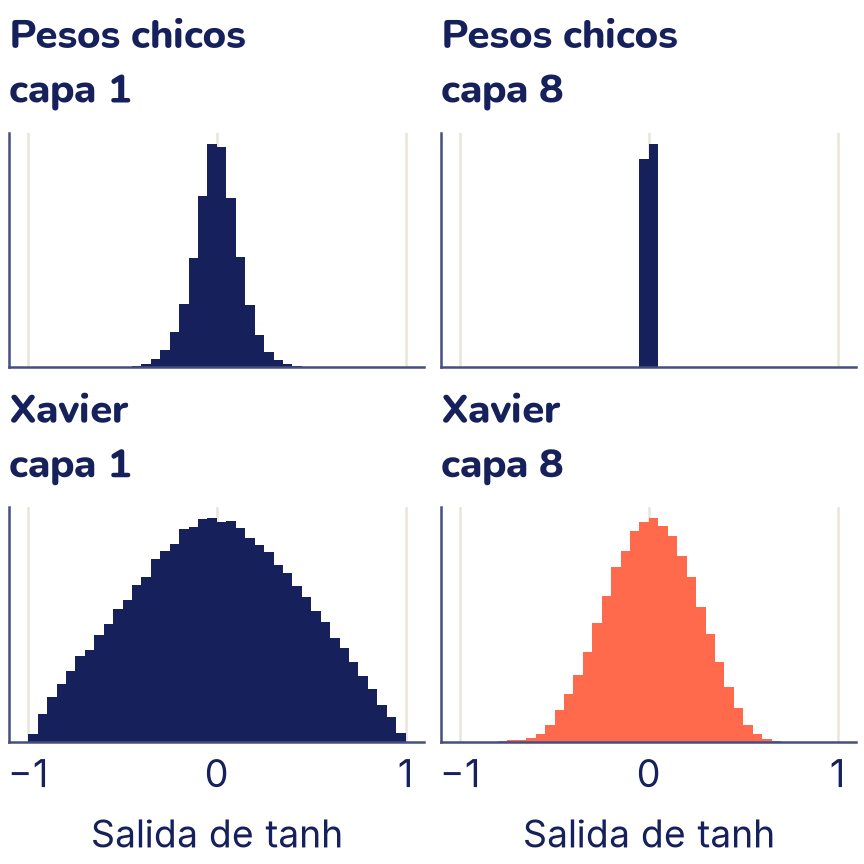

In [ ]:
def activaciones(inicializar, capas=8, ancho=256):
    """Las salidas de cada capa tanh de una red sin entrenar."""
    torch.manual_seed(0)
    a = X_ent[:1000].reshape(1000, -1)
    salidas = []
    with torch.no_grad():
        for i in range(capas):
            capa = nn.Linear(a.shape[1], ancho)
            inicializar(capa.weight)
            nn.init.zeros_(capa.bias)
            a = torch.tanh(capa(a))
            salidas.append(a)
    return salidas

inicios = {
    "pesos chicos (σ = 0,01)": lambda w: nn.init.normal_(w, std=0.01),
    "pesos grandes (σ = 1)": lambda w: nn.init.normal_(w, std=1.0),
    "Xavier": nn.init.xavier_normal_,
}
salidas = {}
for nombre, inicializar in inicios.items():
    salidas[nombre] = activaciones(inicializar)
    primera, octava = salidas[nombre][0], salidas[nombre][-1]
    saturadas = (octava.abs() > 0.99).float().mean().item()
    print(f"{nombre:24s} desviación capa 1: {primera.std():.3f}, "
          f"capa 8: {octava.std():.3f}, saturadas: {saturadas:.0%}")

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8), sharex=True)
chicos = "pesos chicos (σ = 0,01)"
paneles = [(chicos, 0), (chicos, 7), ("Xavier", 0), ("Xavier", 7)]
for eje, (nombre, capa) in zip(ejes.flat, paneles):
    valores = salidas[nombre][capa].flatten().numpy()
    color = "C1" if (nombre == "Xavier" and capa == 7) else "C0"
    eje.hist(valores, bins=np.linspace(-1, 1, 41), color=color)
    eje.set_yticks([])
    titulo = "Pesos chicos" if nombre != "Xavier" else "Xavier"
    eje.set_title(f"{titulo}\ncapa {capa + 1}")
for eje in ejes[1]:
    eje.set_xlabel("Salida de tanh")
plt.show()

Con pesos chicos, la señal se apaga capa a capa: en la octava, la desviación es 0,000 y todas las salidas son prácticamente cero. Con pesos grandes pasa lo contrario: el 87 % de las salidas de la octava capa están saturadas, pegadas a −1 o a 1, donde tanh es plana y el gradiente casi no pasa. Con Xavier, la señal llega viva a la capa 8 (desviación 0,232) y sin saturarse.

## Normalización por lotes

La inicialización cuida que las señales tengan un buen tamaño **al empezar**. Pero los pesos cambian al entrenar, y las señales que llegan a cada capa cambian con ellos. La **normalización por lotes** (*batch normalization*) cuida el tamaño **todo el tiempo**: es una capa que, para cada neurona, toma los valores de todo el mini-lote y los **estandariza** (les resta su media y los divide por su desviación estándar, como en el tema 5). Después los multiplica y les suma dos números que sí se aprenden, para que la red pueda elegir la escala que le convenga.

Tiene una sutileza importante. Al **entrenar**, usa la media y la desviación del lote actual. Al **evaluar**, puede llegar una sola imagen, y la media de una imagen no dice nada; entonces usa unos promedios que fue acumulando durante el entrenamiento. Por eso es obligatorio llamar a `modelo.eval()` antes de evaluar (la función `evaluar` lo hace) y a `modelo.train()` antes de seguir entrenando (lo hace `entrenar`).

In [ ]:
bn = nn.BatchNorm1d(2)            # dos neuronas
lote = torch.tensor([[1.0, 100.0], [2.0, 300.0], [3.0, 500.0]])

bn.train()
print("Entrenando:")
print(bn(lote).detach().numpy().round(2))
print("Promedios acumulados:", bn.running_mean.numpy().round(1))
bn.eval()
print("Evaluando:")
print(bn(lote).detach().numpy().round(1))

Entrenando:
[[-1.22 -1.22]
 [ 0.    0.  ]
 [ 1.22  1.22]]
Promedios acumulados: [ 0.2 30. ]
Evaluando:
[[0.8 1.1]
 [1.8 4.3]
 [2.8 7.4]]


En modo entrenamiento, cada columna sale estandarizada con la media y la desviación de **este** lote: −1,22, 0 y 1,22 en las dos, aunque la segunda tenía números cien veces más grandes. Los promedios acumulados avanzan un 10 % hacia la media de cada lote: de 0 a 0,2 y a 30, porque las medias de este lote son 2 y 300. En modo evaluación la capa usa esos promedios, que con un solo lote todavía están lejos de los reales, y la salida es muy distinta. Tras cientos de lotes de entrenamiento, los promedios se parecen a los de los datos. Lo importante: **el mismo modelo da resultados distintos según el modo**, y olvidar `eval()` es un error común y difícil de ver.

¿Para qué sirve? Hace el entrenamiento mucho más estable y permite redes más profundas y tasas más altas. Un caso extremo: una red de seis capas ocultas con sigmoide, que satura con facilidad, entrenada con SGD. En PyTorch, `nn.BatchNorm1d` va entre la capa lineal y la activación:

In [ ]:
def red_profunda(con_bn):
    """Seis capas ocultas de 128 con sigmoide, con o sin BatchNorm."""
    capas, entrada = [nn.Flatten()], 784
    for _ in range(6):
        capas.append(nn.Linear(entrada, 128))
        if con_bn:
            capas.append(nn.BatchNorm1d(128))
        capas.append(nn.Sigmoid())
        entrada = 128
    capas.append(nn.Linear(128, 10))
    # *capas pasa cada elemento de la lista como un argumento aparte
    return nn.Sequential(*capas)

for con_bn in [False, True]:
    torch.manual_seed(0)
    modelo = red_profunda(con_bn)
    cargador_ent, cargador_val = cargadores()
    optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
    h = entrenar(modelo, cargador_ent, cargador_val, 5, optimizador,
                 dispositivo=device, mostrar=False)
    nombre = "con BatchNorm" if con_bn else "sin BatchNorm"
    print(f"{nombre}: exactitud de validación por época",
          np.round(h["exactitud_val"], 3))

sin BatchNorm: exactitud de validación por época [0.091 0.094 0.111 0.106 0.094]
con BatchNorm: exactitud de validación por época [0.734 0.754 0.754 0.804 0.768]


Sin normalización, la red profunda no aprende nada en cinco épocas: se queda alrededor del 10 %, lo que da adivinar. Las señales se achican al pasar por seis sigmoides y los gradientes que llegan a las primeras capas son diminutos. Con BatchNorm, la misma red con la misma tasa llega a 73,4 % en la primera época y a 80,4 % en la cuarta. No es la única forma de rescatar esta red, pero la normalización por lotes es una de las piezas que hicieron posible entrenar redes muy profundas.

## Regularización: que la red no memorice

En el tema 7 viste el **sobreajuste**: un modelo muy flexible aprende de memoria los datos de entrenamiento, ruido incluido, y le va peor con datos nuevos. Las redes neuronales tienen tantos parámetros que sobreajustan con facilidad, sobre todo con pocos datos. Provoquémoslo: una red con dos capas ocultas de 256 neuronas (unos 270 000 pesos) y solo **1000** imágenes de entrenamiento, durante 40 épocas.

Vamos a probar dos remedios.

**Dropout.** En cada paso de entrenamiento, cada neurona de la capa se **apaga al azar** con probabilidad *p* (su salida se vuelve cero) y las que quedan se multiplican por 1 / (1 − *p*), para que la suma no cambie en promedio. La red no puede depender de ninguna neurona en particular: es como un equipo que entrena sabiendo que cualquiera puede faltar, y entonces nadie se vuelve imprescindible. Al evaluar, con `modelo.eval()`, el dropout se desactiva y todas las neuronas trabajan. En PyTorch es la capa `nn.Dropout(p)`, después de la activación.

**Decaimiento de pesos** (*weight decay*). Es la idea de Ridge del tema 7 (castigar los pesos grandes), escrita como un paso del optimizador: en cada paso, además de seguir el gradiente, cada peso se **encoge** un poquito hacia cero:

$$w \leftarrow w - \alpha \cdot ( \text{paso del optimizador} ) - \alpha \cdot \lambda \cdot w$$

Con SGD, encoger así es exactamente lo mismo que sumar *λ*/2 · Σ *w*² a la pérdida (la regularización **L2**, la de Ridge). Con Adam **no** es lo mismo: si el castigo L2 se suma a la pérdida, su gradiente pasa por la división de Adam, y los pesos con gradientes grandes terminan casi sin castigo. **AdamW** aplica el encogimiento aparte, directo sobre el peso, como en la fórmula de arriba: el castigo es parejo para todos los pesos. Por eso, si usas Adam con decaimiento de pesos, usa `AdamW`. Ojo: en `torch.optim.Adam` el argumento `weight_decay` hace la versión L2, no la de AdamW.

Sin regularización pérdida de validación: mínima 0.640 (época 12), final 0.957
Dropout 0,5        pérdida de validación: mínima 0.620 (época 31), final 0.653
Decaimiento 1      pérdida de validación: mínima 0.632 (época 13), final 0.773


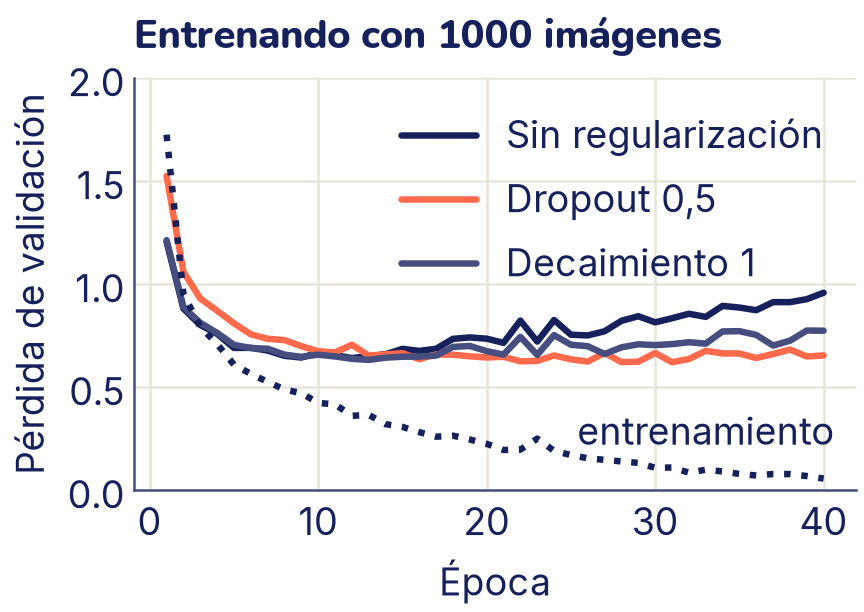

In [ ]:
def red_grande(p_dropout=0.0):
    """Dos capas ocultas de 256, con dropout opcional."""
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 256), nn.ReLU(), nn.Dropout(p_dropout),
        nn.Linear(256, 256), nn.ReLU(), nn.Dropout(p_dropout),
        nn.Linear(256, 10))

# Pocos datos: solo 1000 imágenes de entrenamiento
experimentos = {"Sin regularización": (0.0, 0.0),
                "Dropout 0,5": (0.5, 0.0),
                "Decaimiento 1": (0.0, 1.0)}
regs = {}
for nombre, (p_dropout, decaimiento) in experimentos.items():
    torch.manual_seed(0)
    modelo = red_grande(p_dropout)
    cargador_poco, cargador_val = cargadores(64, X_ent[:1000],
                                             y_ent[:1000])
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=0.001,
                                    weight_decay=decaimiento)
    regs[nombre] = entrenar(modelo, cargador_poco, cargador_val, 40,
                            optimizador, dispositivo=device,
                            mostrar=False)
    pv = regs[nombre]["perdida_val"]
    print(f"{nombre:18s} pérdida de validación: mínima {min(pv):.3f} "
          f"(época {np.argmin(pv) + 1}), final {pv[-1]:.3f}")

colores = {"Sin regularización": "C0", "Dropout 0,5": "C1",
           "Decaimiento 1": "C2"}
epocas = range(1, 41)
for nombre, h in regs.items():
    plt.plot(epocas, h["perdida_val"], color=colores[nombre],
             label=nombre)
# La de entrenamiento, punteada, solo para la red sin regularizar
plt.plot(epocas, regs["Sin regularización"]["perdida_ent"], color="C0",
         linestyle=":")
plt.text(33, 0.22, "entrenamiento", color="C0", ha="center")
plt.ylim(0, 2)
plt.xlabel("Época")
plt.ylabel("Pérdida de validación")
plt.title("Entrenando con 1000 imágenes")
plt.legend(loc="upper right")
plt.show()

La red sin regularizar es el sobreajuste de libro: su pérdida de entrenamiento baja casi a cero, pero la de validación toca fondo en la época 12 (0,640) y desde ahí sube hasta 0,957. La red memoriza las 1000 fotos. Con dropout, la pérdida de validación baja más despacio, pero sigue mejorando hasta la época 31 (0,620) y al final apenas subió (0,653). El decaimiento de pesos frena el sobreajuste a medias: termina en 0,773.

El valor de cada perilla (la *p* del dropout, el *λ* del decaimiento de pesos) se elige, como siempre, mirando la validación; aquí probamos un solo valor de cada una. ¿Por qué un decaimiento de 1, que parece enorme? Porque en AdamW se multiplica por la tasa: en cada paso, cada peso se encoge en una fracción *α* · *λ* = 0,001 · 1 = 0,001 de su valor.

### Más datos, aunque sean inventados

El mejor remedio contra el sobreajuste son más datos. Cuando no los hay, a veces se pueden fabricar: una foto de una zapatilla corrida dos píxeles, un poco girada o reflejada sigue siendo una zapatilla. Esto se llama **aumentación de datos**: en cada época la red ve versiones algo distintas de cada imagen y le cuesta más memorizarlas. Lo vas a usar con las redes convolucionales en el tema 20.

## Parada temprana

Mira otra vez la curva sin regularización: la pérdida de validación baja, toca fondo y después sube. La red de la época del fondo era mejor que la del final. La **parada temprana** (*early stopping*) aprovecha esto: después de cada época mira la pérdida de validación, guarda una copia de los pesos cada vez que mejora y, si pasan varias épocas seguidas sin mejorar, se detiene y recupera la mejor copia. Ese número de épocas de espera se llama **paciencia**: la pérdida de validación sube y baja un poco por azar, y no queremos parar por un solo tropiezo.

La función `entrenar` no trae parada temprana, pero no hace falta cambiarla: la llamamos una época a la vez.

Paro en la época 17: 5 épocas sin mejorar desde la época 12
Pesos recuperados de la época 12: pérdida 0.640, exactitud 0.773


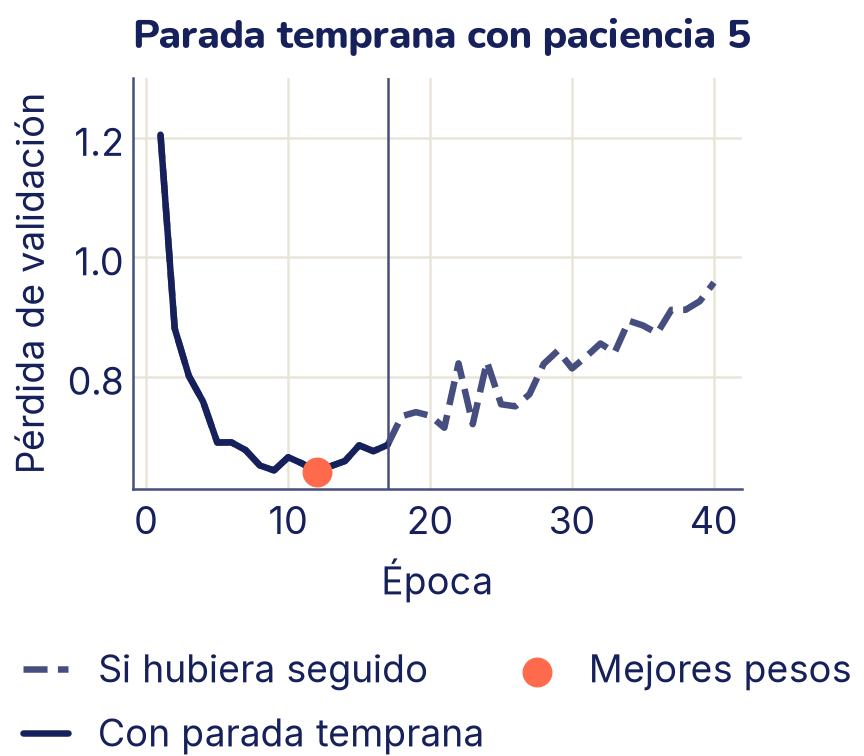

In [ ]:
def entrenar_con_paciencia(modelo, cargador_ent, cargador_val,
                           optimizador, paciencia=5, max_epocas=100):
    """Entrena hasta que la validación no mejora en `paciencia` épocas.

    Devuelve el historial y la época de los mejores pesos, que deja
    cargados en `modelo`.
    """
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    mejor_perdida, mejor_epoca = float("inf"), 0
    # deepcopy hace una copia independiente: si los pesos siguen
    # cambiando, la copia guardada no cambia con ellos
    mejores_pesos = copy.deepcopy(modelo.state_dict())
    for epoca in range(1, max_epocas + 1):
        h = entrenar(modelo, cargador_ent, cargador_val, 1, optimizador,
                     dispositivo=device, mostrar=False)
        for clave in historial:
            historial[clave] += h[clave]
        if h["perdida_val"][0] < mejor_perdida:
            mejor_perdida, mejor_epoca = h["perdida_val"][0], epoca
            mejores_pesos = copy.deepcopy(modelo.state_dict())
        elif epoca - mejor_epoca >= paciencia:
            print(f"Paro en la época {epoca}: {paciencia} épocas "
                  f"sin mejorar desde la época {mejor_epoca}")
            break
    modelo.load_state_dict(mejores_pesos)
    return historial, mejor_epoca


torch.manual_seed(0)
modelo = red_grande()
cargador_poco, cargador_val = cargadores(64, X_ent[:1000], y_ent[:1000])
optimizador = torch.optim.AdamW(modelo.parameters(), lr=0.001,
                                weight_decay=0.0)
h_parada, mejor_epoca = entrenar_con_paciencia(
    modelo, cargador_poco, cargador_val, optimizador, max_epocas=40)
perdida, exactitud = evaluar(modelo, cargador_val, nn.CrossEntropyLoss(),
                             dispositivo=device)
print(f"Pesos recuperados de la época {mejor_epoca}: pérdida "
      f"{perdida:.3f}, exactitud {exactitud:.3f}")

completa = regs["Sin regularización"]["perdida_val"]
# Una figura más alta, para dejar lugar a la leyenda debajo
plt.figure(figsize=(4.8, 4.2))
plt.plot(range(1, 41), completa, color="C2", linestyle="--",
         label="Si hubiera seguido")
plt.plot(range(1, len(h_parada["perdida_val"]) + 1),
         h_parada["perdida_val"], color="C0", label="Con parada temprana")
plt.scatter([mejor_epoca], [completa[mejor_epoca - 1]], color="C1",
            s=120, zorder=3, label="Mejores pesos")
plt.axvline(len(h_parada["perdida_val"]), color="C2", linewidth=1)
plt.xlabel("Época")
plt.ylabel("Pérdida de validación")
plt.ylim(top=1.3)
plt.title("Parada temprana con paciencia 5")
# Leyenda debajo del gráfico, para que la línea vertical no la cruce
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2,
           frameon=False, handlelength=1.2, columnspacing=0.8)
plt.show()

La mejor pérdida fue la de la época 12; las cinco siguientes no la mejoraron y en la 17 el entrenamiento se detuvo, 23 épocas antes de lo previsto. Los pesos que quedan en el modelo son los de la época 12: pérdida 0,640 y exactitud de 77,3 %, en lugar de la pérdida de 0,957 que habríamos tenido al final.

La parada temprana usa el conjunto de **validación** para decidir cuándo parar: es elegir un hiperparámetro (el número de épocas). Por eso la exactitud de esa época es un poco optimista y, como en el tema 7, la medida final honesta se hace con el conjunto de prueba, una sola vez.

### Una red demasiado segura: el escalado de temperatura

**Para profundizar (opcional).** En el tema 9 viste la **calibración**: un modelo está bien calibrado si, cuando dice «80 %», acierta el 80 % de las veces. Las redes sobreajustadas suelen estar **demasiado seguras**: como aprendieron de memoria el entrenamiento, su softmax da probabilidades muy cerca de 1 aunque se equivoquen seguido. Por eso la pérdida de validación de la red sin regularizar subió hasta 0,957 mientras su exactitud casi no cambiaba: cada error lo cometía con mucha seguridad.

El remedio más simple es el **escalado de temperatura** (*temperature scaling*): antes del softmax, dividir todos los logits por un mismo número *T*, la **temperatura**. Con *T* mayor que 1 las probabilidades se aplanan y la red queda menos segura; con *T* menor que 1, se afilan. Como todos los logits se dividen por el mismo número positivo, el más grande sigue siendo el más grande: **la exactitud no cambia**. *T* es un solo número y se elige minimizando la entropía cruzada en datos que la red no usó ni para entrenar ni para elegir sus épocas. Aquí tomamos otras 1000 imágenes del entrenamiento original; la prueba sigue sin tocarse.

In [ ]:
# Otras 1000 imágenes que ni el entrenamiento ni la validación usaron
X_temp, y_temp = X[8000:9000], y[8000:9000]
torch.manual_seed(0)
sobre = red_grande()          # la red sin regularizar, 40 épocas
cargador_poco, cargador_val = cargadores(64, X_ent[:1000], y_ent[:1000])
optimizador = torch.optim.AdamW(sobre.parameters(), lr=0.001,
                                weight_decay=0.0)
entrenar(sobre, cargador_poco, cargador_val, 40, optimizador,
         dispositivo=device, mostrar=False)
sobre.eval()
with torch.no_grad():
    z_temp = sobre(X_temp.to(device)).cpu()     # logits
    z_val = sobre(X_val.to(device)).cpu()
# Aprendemos log(T) y no T, para que T = e^log(T) sea siempre positiva
log_t = torch.zeros(1, requires_grad=True)
opt_t = torch.optim.Adam([log_t], lr=0.05)
for paso in range(300):
    opt_t.zero_grad()
    perdida_t = nn.functional.cross_entropy(z_temp / log_t.exp(), y_temp)
    perdida_t.backward()
    opt_t.step()
temperatura = log_t.exp().item()

for t in [1.0, temperatura]:
    prob = (z_val / t).softmax(dim=1)
    print(f"T = {t:.2f}: pérdida de validación "
          f"{nn.functional.cross_entropy(z_val / t, y_val).item():.3f}, "
          f"confianza media {prob.max(dim=1).values.mean().item():.3f}, "
          f"exactitud {(prob.argmax(dim=1) == y_val).float().mean():.3f}")

T = 1.00: pérdida de validación 0.957, confianza media 0.917, exactitud 0.780
T = 2.45: pérdida de validación 0.638, confianza media 0.783, exactitud 0.780


La **confianza media** es el promedio de la probabilidad más alta que da la red en cada imagen; si la red está bien calibrada, tiene que parecerse a su exactitud. Sin temperatura, la red dice estar segura en un 91,7 % y acierta el 78,0 %. Con *T* = 2,45, la confianza baja a 78,3 %, casi igual a la exactitud, y la pérdida de validación cae de 0,957 a 0,638, incluso un poco por debajo del mínimo que tuvo en la época 12 (0,640). La exactitud no se movió: la temperatura no corrige errores, solo hace que la red diga con honestidad cuánto sabe. Son pocas líneas y no hay que volver a entrenar, por eso es lo primero que se prueba cuando las probabilidades de una red se van a usar como números.

## Cómo diagnosticar un entrenamiento

Con todo lo anterior ya puedes leer las curvas de un entrenamiento como un médico lee un análisis. Primero, una receta para empezar cualquier proyecto: **antes de entrenar con todos los datos, comprueba que la red puede sobreajustar un lote pequeño**. Con 32 imágenes y suficientes pasos, una red sana tiene que llegar a pérdida casi cero y acertarlas todas. Si no lo logra, hay un error en el código (la pérdida, las etiquetas, el optimizador) y no tiene sentido seguir con los datos completos.

In [ ]:
torch.manual_seed(0)
modelo = mlp()
lote_chico = DataLoader(TensorDataset(X_ent[:32], y_ent[:32]),
                        batch_size=32)
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
# Entrenamos y "validamos" con el mismo lote: solo queremos memorizarlo
h = entrenar(modelo, lote_chico, lote_chico, 100, optimizador,
             dispositivo=device, mostrar=False)
# Hay un solo lote: cada época es un paso
for paso in [1, 10, 50, 100]:
    print(f"Paso {paso:3d}: pérdida {h['perdida_val'][paso - 1]:.4f}, "
          f"exactitud {h['exactitud_val'][paso - 1]:.2f}")

Paso   1: pérdida 1.9704, exactitud 0.56
Paso  10: pérdida 0.8034, exactitud 0.91
Paso  50: pérdida 0.0177, exactitud 1.00
Paso 100: pérdida 0.0043, exactitud 1.00


En 50 pasos la red ya acierta las 32 imágenes, y en 100 la pérdida es casi cero. La red y el bucle funcionan; recién ahora tiene sentido entrenar con todos los datos. (Que memorice 32 imágenes no dice nada de cómo le irá con imágenes nuevas: esta prueba solo busca errores en el código.)

Y estas son las curvas que más vas a ver, con lo que conviene hacer en cada caso:

| Lo que ves | Diagnóstico | Qué probar |
|---|---|---|
| La pérdida de entrenamiento sube, salta o da `nan` | Tasa **demasiado alta** | Dividir la tasa por 3 o por 10; calentamiento |
| Las dos pérdidas bajan, pero muy despacio | Tasa **demasiado baja** u optimizador lento | Subir la tasa (buscador de tasa); Adam o momentum |
| Las dos pérdidas se quedan altas y planas, juntas | **Subajuste**: la red no alcanza | Red más grande, más épocas, revisar los datos |
| La de entrenamiento sigue bajando y la de validación sube | **Sobreajuste** | Dropout, decaimiento de pesos, parada temprana, más datos o aumentación |
| Las dos bajan y la de validación se aplana cerca de la de entrenamiento | **Sano** | Parar cuando deje de mejorar; probar a subir la capacidad |
| Muy ruidosa de un lote a otro | Lotes muy chicos o tasa algo alta | Lotes más grandes, tasa más baja, momentum |

**Cambia una sola cosa a la vez.** Si cambias tres cosas y mejora, no sabes cuál ayudó (ni si alguna perjudicó). Es lo que vas a practicar en el mini-proyecto.

## Lo que aprendiste y lo que sigue

- El gradiente se calcula con **mini-lotes**: son un punto medio entre el descenso completo (caro por paso) y el estocástico (muy ruidoso).
- **Momentum** acumula velocidad y cruza los valles estrechos; **Adam** adapta el paso a cada peso; **AdamW** aplica bien el decaimiento de pesos. Adam o AdamW con tasa 0,001 es un buen punto de partida.
- Un **buscador de tasa** encuentra una zona razonable en una pasada, y un **programador** (escalera, coseno, calentamiento) cambia la tasa durante el entrenamiento.
- Los pesos se inicializan **al azar** para romper la simetría, con una escala (**Xavier**, **He**) que mantiene el tamaño de las señales. La **normalización por lotes** lo mantiene durante todo el entrenamiento y se comporta distinto al entrenar y al evaluar.
- **Dropout**, **decaimiento de pesos** y **parada temprana** frenan el sobreajuste. Las curvas de entrenamiento y validación dicen cuál es el problema.

En el tema 20 cambia la arquitectura: las **redes convolucionales**, hechas para imágenes. Todo lo de este tema (Adam, BatchNorm, dropout, aumentación, parada temprana) se usa allí tal cual.

# Ejercicios

## Antes de empezar

Los ejercicios usan lo que definiste en la teoría: los datos `X_ent`, `y_ent`, `X_val` e `y_val`, las funciones `cargadores`, `mlp`, `entrenar`, `evaluar`, `red_grande` y `entrenar_con_paciencia`, y el diccionario `regs` con los historiales de la sección de regularización. Ejecuta en orden los bloques de la ficha Código en un cuaderno de Colab y trabaja debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. Momentum a mano

Bajamos por *f*(*w*) = *w*², cuyo gradiente es 2*w*, desde *w* = 1 con tasa *α* = 0,1. Calcula a mano los tres primeros pasos de SGD y los tres primeros de momentum con *β* = 0,9 (empieza con *v* = 0). ¿Cuál llega más cerca del mínimo, *w* = 0? ¿Qué crees que le pasa al momentum en los pasos siguientes? Después compruébalo con `torch.optim.SGD`.

<details>
<summary>Respuesta</summary>

**SGD**: cada paso multiplica *w* por 1 − 0,1 · 2 = 0,8. Queda 0,8, después 0,64 y después 0,512.

**Momentum**:

- Paso 1: *g* = 2, *v* = 0,9 · 0 + 2 = 2, *w* = 1 − 0,1 · 2 = 0,8.
- Paso 2: *g* = 1,6, *v* = 0,9 · 2 + 1,6 = 3,4, *w* = 0,8 − 0,34 = 0,46.
- Paso 3: *g* = 0,92, *v* = 0,9 · 3,4 + 0,92 = 3,98, *w* = 0,46 − 0,398 = 0,062.

El primer paso es igual (todavía no hay nada acumulado). Desde el segundo, la velocidad suma los gradientes anteriores y el momentum avanza mucho más: en tres pasos queda en 0,062, contra 0,512 de SGD. Pero la velocidad no se frena de golpe: en el paso siguiente se pasa del mínimo y queda del otro lado, y después oscila alrededor de 0 mientras la velocidad se va apagando.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def primeros_pasos(momentum, pasos=5):
    w = torch.tensor([1.0], requires_grad=True)
    optimizador = torch.optim.SGD([w], lr=0.1, momentum=momentum)
    valores = []
    for _ in range(pasos):
        optimizador.zero_grad()
        (w ** 2).sum().backward()
        optimizador.step()
        valores.append(round(w.item(), 3))
    return valores

print("SGD:     ", primeros_pasos(0.0))
print("Momentum:", primeros_pasos(0.9))

### 2. El primer paso de Adam

Tres pesos, cada uno en una función distinta: *f*(*w*) = 0,001 · *w*, *f*(*w*) = *w* y *f*(*w*) = 1000 · *w*. Sus gradientes son 0,001, 1 y 1000. Con SGD y tasa 0,1, ¿cuánto se mueve cada uno en el primer paso? ¿Y con Adam y tasa 0,1? Usa la fórmula de la teoría con la corrección de Adam: como *m* y *s* empiezan en 0, en el paso *t* Adam no usa *m* y *s* sino *m* / (1 − *β*<sub>1</sub><sup>*t*</sup>) y *s* / (1 − *β*<sub>2</sub><sup>*t*</sup>). Calcula primero *m*, *s* y sus versiones corregidas en el paso *t* = 1, con *β*<sub>1</sub> = 0,9 y *β*<sub>2</sub> = 0,999.

<details>
<summary>Respuesta</summary>

Con SGD, el paso es tasa × gradiente: 0,0001, 0,1 y 100. Mil veces más grande cada vez.

Con Adam, en el paso 1: *m* = 0,9 · 0 + 0,1 · *g* = 0,1 · *g*, y la corrección lo divide por 1 − 0,9 = 0,1, así que queda exactamente *g*. Igual con *s*: *s* = 0,001 · *g*², dividido por 1 − 0,999 = 0,001, da exactamente *g*². Sin la corrección, *m* sería diez veces más chico que el gradiente y *s* mil veces más chico que *g*²: los primeros pasos saldrían de un tamaño equivocado. Con ella, el primer paso es *α* · *g* / (√(*g*²) + *ε*) = *α* · *g* / |*g*|, es decir, *α* con el signo del gradiente: los **tres** se mueven 0,1 (salvo el *ε*, que se nota un poquito cuando el gradiente es diminuto). Es la idea de Adam llevada al extremo: el largo del paso no depende del tamaño del gradiente, solo de su dirección y de la tasa.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for escala in [0.001, 1.0, 1000.0]:
    movimientos = []
    for crear in [lambda q: torch.optim.SGD(q, lr=0.1),
                  lambda q: torch.optim.Adam(q, lr=0.1)]:
        w = torch.tensor([0.0], requires_grad=True)
        optimizador = crear([w])
        (escala * w).sum().backward()
        optimizador.step()
        movimientos.append(-w.item())
    print(f"Gradiente {escala:7g}: SGD se mueve {movimientos[0]:9.4f}, "
          f"Adam {movimientos[1]:.4f}")

### 3. Diagnosticar seis entrenamientos

Cada panel muestra la pérdida de entrenamiento (a rayas) y la de validación (continua) de un entrenamiento con FashionMNIST. Para cada uno, di qué está pasando y qué cambiarías. La tabla del final de la teoría te puede ayudar.

In [ ]:
# @title El código que hizo las curvas (muestra cómo se entrenó cada una: ábrelo al final): código (doble clic para verlo)
def curvas_de(crear_modelo, crear_optimizador, lote=64, epocas=15):
    """Entrena 15 épocas y devuelve el historial."""
    torch.manual_seed(0)
    modelo = crear_modelo()
    cargador_ent, cargador_val = cargadores(lote)
    return entrenar(modelo, cargador_ent, cargador_val, epocas,
                    crear_optimizador(modelo.parameters()),
                    dispositivo=device, mostrar=False)

una_neurona = lambda: nn.Sequential(nn.Flatten(), nn.Linear(784, 1),
                                    nn.ReLU(), nn.Linear(1, 10))
casos = {
    "A": regs["Sin regularización"],
    "B": curvas_de(mlp, lambda p: torch.optim.SGD(p, lr=0.001)),
    "C": curvas_de(mlp, lambda p: torch.optim.SGD(p, lr=1.0)),
    "D": regs["Dropout 0,5"],
    "E": curvas_de(una_neurona, lambda p: torch.optim.Adam(p, lr=0.01)),
    "F": curvas_de(mlp, lambda p: torch.optim.SGD(p, lr=0.3), lote=8),
}


def dibujar(eje, letra):
    h = casos[letra]
    epocas = range(1, len(h["perdida_val"]) + 1)
    eje.plot(epocas, h["perdida_ent"], color="C2", linestyle="--",
             label="Entrenamiento")
    eje.plot(epocas, h["perdida_val"], color="C0", label="Validación")
    eje.set_ylim(0, 2.5)
    eje.set_title(letra)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, letra in zip(ejes.flat, "ABCD"):
    dibujar(eje, letra)
for eje in ejes[1]:
    eje.set_xlabel("Época")
for eje in ejes[:, 0]:
    eje.set_ylabel("Pérdida")
plt.show()

fig, ejes = plt.subplots(1, 2, sharey=True)
for eje, letra in zip(ejes, "EF"):
    dibujar(eje, letra)
    eje.set_xlabel("Época")
ejes[0].set_ylabel("Pérdida")
ejes[1].legend(loc="upper right")
plt.show()

<details>
<summary>Respuesta</summary>

- **A, sobreajuste.** La pérdida de entrenamiento baja casi a cero y la de validación toca fondo y sube. Probaría dropout, decaimiento de pesos o parada temprana, y si se puede, más datos o aumentación.
- **B, tasa demasiado baja.** Las dos bajan juntas, en línea casi recta y muy despacio: después de 15 épocas siguen en 1,6. Subiría la tasa (por ejemplo, ×10), usaría el buscador de tasa o cambiaría a momentum o Adam.
- **C, tasa demasiado alta.** La pérdida salta alrededor de 2 y nunca baja de verdad (una red que adivina al azar entre diez clases tiene pérdida 2,3). Bajaría la tasa, dividiéndola por 10.
- **D, sano.** Las dos bajan y la de validación se aplana sin subir. Se puede parar cuando deje de mejorar; si se quiere más, probar una red más grande o más datos.
- **E, subajuste.** Las dos pérdidas están juntas, pero se quedan altas y planas: la red no tiene capacidad para más. Usaría una red más grande.
- **F, demasiado ruido.** La pérdida de entrenamiento baja bien, pero la de validación salta de una época a otra y al final da un salto grande: los pasos son demasiado bruscos. Usaría lotes más grandes o una tasa más baja (o un programador que la baje al final).

Cómo se entrenaron: A es la red sin regularizar de la teoría, con 1000 imágenes; B, SGD con tasa 0,001; C, SGD con tasa 1; D, la red con dropout 0,5 de la teoría; E, una red con **una sola** neurona oculta; F, SGD con tasa 0,3 y lotes de 8 imágenes. Fíjate en que D no es perfecta: su pérdida de entrenamiento queda bastante por debajo de la de validación. Con 1000 imágenes, algo de diferencia es inevitable; lo que importa es que la de validación ya no sube.

</details>

### 4. Tamaño de lote frente a tasa

Entrena el MLP de la teoría con SGD (sin momentum) durante tres épocas, con lotes de 16, 64 y 256 imágenes y tasas de 0,01, 0,05 y 0,2: nueve entrenamientos. Arma una tabla con la exactitud de validación. ¿La mejor tasa es la misma para todos los tamaños de lote? ¿Qué patrón ves?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
import pandas as pd

tabla = {}
for lote in [16, 64, 256]:
    fila = {}
    for tasa in [0.01, 0.05, 0.2]:
        torch.manual_seed(0)
        modelo = mlp()
        cargador_ent, cargador_val = cargadores(lote)
        optimizador = torch.optim.SGD(modelo.parameters(), lr=tasa)
        h = entrenar(modelo, cargador_ent, cargador_val, 3, optimizador,
                     dispositivo=device, mostrar=False)
        fila[f"tasa {tasa}"] = h["exactitud_val"][-1]
    tabla[f"lote {lote}"] = fila
print(pd.DataFrame(tabla).T.round(3))

<details>
<summary>Respuesta</summary>

La mejor tasa **no** es la misma. Con lotes de 16, la tasa 0,05 ya da lo mejor (0,803), y 0,2 casi lo mismo (0,800). Con lotes de 64 y de 256, la mejor es 0,2, la más grande que probamos, y con 256 la diferencia es enorme: 0,590 con tasa 0,01 y 0,730 con 0,2.

El patrón: **los lotes grandes piden tasas más grandes**. Con lotes grandes hay menos pasos por época, así que cada paso tiene que llegar más lejos, y como su gradiente es más confiable (menos ruidoso), aguanta pasos más largos. Una regla práctica muy usada: si multiplicas el lote por *k*, prueba a multiplicar la tasa por algo parecido a *k*, hasta cierto límite. Por eso, al cambiar el tamaño del lote, hay que volver a buscar la tasa.

Fíjate también en que, con el mismo número de épocas, los lotes chicos llegan más lejos: dan más pasos. La tabla no mide el tiempo; con lotes más grandes cada época tarda menos, sobre todo en una GPU.

</details>

### 5. Dropout por dentro

Pasa un tensor de diez unos por `nn.Dropout(0.5)`, primero en modo entrenamiento y después en modo evaluación. ¿Qué valores salen? ¿Por qué aparecen doses?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
torch.manual_seed(0)
capa = nn.Dropout(0.5)
unos = torch.ones(10)
capa.train()
print("Entrenando:", capa(unos).tolist())
capa.eval()
print("Evaluando: ", capa(unos).tolist())

<details>
<summary>Respuesta</summary>

En modo entrenamiento, cada valor se apagó (0) o sobrevivió con probabilidad 0,5. Esta vez sobrevivieron 4 de 10 (es al azar: en promedio serían 5). Los que sobreviven se multiplican por 1 / (1 − 0,5) = 2, para que el promedio de la salida siga siendo más o menos 1 y la capa siguiente reciba señales del mismo tamaño que al evaluar. En modo evaluación, el dropout no hace nada: los diez unos pasan iguales.

</details>

### 6. ¿Qué guarda BatchNorm?

¿Cuántos números **aprende** una capa `nn.BatchNorm1d(256)`? ¿Y cuántos más guarda sin aprenderlos con el gradiente? Razónalo y compruébalo con `parameters()` y `buffers()`.

<details>
<summary>Respuesta</summary>

Aprende dos números por neurona: el que multiplica y el que suma después de estandarizar. Son 2 · 256 = **512** parámetros. Además guarda, sin aprenderlos con el gradiente, los promedios acumulados que usa al evaluar: la media y la varianza de cada neurona (otros 512 números) y un contador de cuántos lotes vio.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
bn = nn.BatchNorm1d(256)
for nombre, p in bn.named_parameters():
    print("Parámetro:", nombre, tuple(p.shape))
for nombre, b in bn.named_buffers():
    print("Guardado: ", nombre, tuple(b.shape))
print("Total aprendido:", sum(p.numel() for p in bn.parameters()))

<details>
<summary>Respuesta (sigue)</summary>

Los «guardados» (*buffers*) forman parte del `state_dict`: se guardan y se cargan con el modelo, porque sin ellos la capa no sabría qué hacer en modo evaluación.

</details>

### 7. Encuentra el error: predicciones que cambian

Una estudiante entrena una red con dropout y después la usa para clasificar las primeras ocho imágenes de validación. Corre su código dos veces seguidas y obtiene predicciones distintas. ¿Qué le falta?

In [ ]:
torch.manual_seed(0)
modelo = red_grande(0.5)
cargador_ent, cargador_val = cargadores()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
h = entrenar(modelo, cargador_ent, cargador_val, 1, optimizador,
             dispositivo=device, mostrar=False)

modelo.train()            # (así quedó después de entrenar)
with torch.no_grad():
    print("Primera vez:", modelo(X_val[:8]).argmax(dim=1).tolist())
    print("Segunda vez:", modelo(X_val[:8]).argmax(dim=1).tolist())

Primera vez: [5, 2, 8, 0, 0, 9, 2, 1]
Segunda vez: [5, 4, 8, 0, 0, 9, 4, 1]


<details>
<summary>Respuesta</summary>

Le falta `modelo.eval()`. El modelo quedó en modo entrenamiento, así que el dropout sigue apagando neuronas al azar en cada pasada y dos pasadas con las mismas imágenes dan resultados distintos: aquí cambian la segunda y la séptima predicción. La función `evaluar` llama a `eval()` por dentro, pero el código de predicción propio tiene que hacerlo a mano.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
modelo.eval()
with torch.no_grad():
    print("Primera vez:", modelo(X_val[:8]).argmax(dim=1).tolist())
    print("Segunda vez:", modelo(X_val[:8]).argmax(dim=1).tolist())
print("Etiquetas:  ", y_val[:8].tolist())

<details>
<summary>Respuesta (sigue)</summary>

`torch.no_grad()` y `modelo.eval()` hacen cosas distintas y casi siempre van juntas al predecir: el primero solo evita guardar lo necesario para calcular gradientes (ahorra memoria y tiempo); el segundo cambia el comportamiento de capas como `Dropout` y `BatchNorm`.

</details>

### 8. He para ReLU

Repite el experimento de la inicialización de la teoría con una red de ocho capas de 256 neuronas, pero con **ReLU** en lugar de tanh. Compara la desviación estándar de las salidas de la capa 1 y de la capa 8 con tres inicializaciones: pesos con *σ* = 0,01, Xavier y He (`nn.init.kaiming_normal_` con `nonlinearity="relu"`). ¿Cuál mantiene la señal?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def activaciones_relu(inicializar, capas=8, ancho=256):
    torch.manual_seed(0)
    a = X_ent[:1000].reshape(1000, -1)
    salidas = []
    with torch.no_grad():
        for i in range(capas):
            capa = nn.Linear(a.shape[1], ancho)
            inicializar(capa.weight)
            nn.init.zeros_(capa.bias)
            a = torch.relu(capa(a))
            salidas.append(a)
    return salidas

he = lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")
for nombre, inicializar in [
        ("σ = 0,01", lambda w: nn.init.normal_(w, std=0.01)),
        ("Xavier", nn.init.xavier_normal_), ("He", he)]:
    s = activaciones_relu(inicializar)
    print(f"{nombre:9s} desviación capa 1: {s[0].std():.4f}, "
          f"capa 8: {s[-1].std():.4f}")

<details>
<summary>Respuesta</summary>

Con *σ* = 0,01 la señal muere: en la capa 8 la desviación es 0,0000. Con Xavier también se va apagando, de 0,32 en la capa 1 a 0,035 en la 8: Xavier está pensada para activaciones como tanh, y ReLU pone en cero más o menos la mitad de los valores, así que cada capa pierde un poco de señal. Con **He**, que usa pesos un poco más grandes justamente para compensar eso, la señal se mantiene (0,37 en la capa 1 y 0,45 en la 8). Por eso la regla es Xavier para tanh y sigmoide y He para ReLU.

</details>

### 9. ¿Cuánta paciencia?

Vuelve a entrenar la red sin regularizar de la sección de parada temprana (1000 imágenes), ahora con paciencia 2 y con paciencia 15. ¿En qué época se detiene cada una y qué pesos recupera? ¿Qué riesgo tiene una paciencia muy chica? ¿Y una muy grande? Por último: ¿por qué la parada temprana mira la validación y no el conjunto de prueba?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for paciencia in [2, 15]:
    torch.manual_seed(0)
    modelo = red_grande()
    cargador_poco, cargador_val = cargadores(64, X_ent[:1000],
                                             y_ent[:1000])
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=0.001,
                                    weight_decay=0.0)
    _, mejor = entrenar_con_paciencia(modelo, cargador_poco, cargador_val,
                                      optimizador, paciencia=paciencia,
                                      max_epocas=40)
    perdida, _ = evaluar(modelo, cargador_val, nn.CrossEntropyLoss(),
                         dispositivo=device)
    print(f"Paciencia {paciencia}: mejores pesos de la época {mejor}, "
          f"pérdida de validación {perdida:.3f}")

<details>
<summary>Respuesta</summary>

- Con **paciencia 2**, para en la época 11 y recupera los pesos de la época 9 (pérdida 0,643). Un par de épocas sin mejorar por azar bastaron para detenerla antes del verdadero fondo, que estaba en la época 12. Ese es el riesgo de una paciencia muy chica: parar por un tropiezo.
- Con **paciencia 15**, llega hasta la época 27 y recupera los pesos de la época 12 (pérdida 0,640), los mismos que con paciencia 5 en la teoría. Como siempre se recuperan los mejores pesos, una paciencia grande casi no empeora el resultado: su costo es el **tiempo**, diez épocas más de entrenamiento que no sirvieron para nada.

La parada temprana usa la validación porque elegir la época es elegir un hiperparámetro. Si se eligiera mirando el conjunto de prueba, ese conjunto dejaría de ser «datos que el modelo nunca vio» y la medida final saldría optimista (tema 7).

</details>

## Mini-proyecto: subir la exactitud del MLP, una cosa a la vez

Parte del MLP de la teoría (784 → 256 → 10) entrenado con SGD sin momentum, tasa 0,05, lotes de 64 y diez épocas, con las 6000 imágenes de entrenamiento. Tu objetivo es subir su exactitud de validación **cambiando una sola cosa por vez** y anotando el efecto en una tabla. Fija la regla antes de empezar y aplícala igual a todos los cambios: un cambio se conserva solo si sube la exactitud de validación **al menos 0,5 puntos** (0,005); si sube menos, o baja, la diferencia puede ser azar y se descarta, porque ante un empate conviene la red más simple.

Una lista de cambios para probar, en este orden:

1. Adam con tasa 0,001 en lugar de SGD.
2. Una capa oculta más, de 256 neuronas.
3. `nn.BatchNorm1d` después de cada capa lineal oculta.
4. Dropout de 0,2 después de cada activación.
5. Un programador coseno (usa la sección opcional sobre la tasa; si la saltaste, salta este paso).
6. Veinte épocas con parada temprana (paciencia 4) en lugar de diez fijas.

Al terminar, y solo una vez, mide el modelo final con el **conjunto de prueba** de FashionMNIST (`train=False`), que no usaste para nada. Compara ese número con la exactitud de validación.

<details>
<summary>Una solución</summary>

Una función arma la red con las opciones que se le pidan, y otra entrena y anota. Así cada fila de la tabla es una llamada.

</details>

In [ ]:
# @title Una solución: código (doble clic para verlo)
def red_opciones(capas=1, bn=False, p_dropout=0.0):
    """Un MLP con `capas` ocultas de 256 y piezas opcionales."""
    piezas, entrada = [nn.Flatten()], 784
    for _ in range(capas):
        piezas.append(nn.Linear(entrada, 256))
        if bn:
            piezas.append(nn.BatchNorm1d(256))
        piezas.append(nn.ReLU())
        if p_dropout > 0:
            piezas.append(nn.Dropout(p_dropout))
        entrada = 256
    piezas.append(nn.Linear(256, 10))
    return nn.Sequential(*piezas)


resultados, modelos = [], {}
def probar(cambio, opciones, adam=True, coseno=False, paciencia=None):
    torch.manual_seed(0)
    modelo = red_opciones(**opciones)
    cargador_ent, cargador_val = cargadores()
    if adam:
        optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    else:
        optimizador = torch.optim.SGD(modelo.parameters(), lr=0.05)
    if paciencia:
        h, mejor = entrenar_con_paciencia(
            modelo, cargador_ent, cargador_val, optimizador,
            paciencia=paciencia, max_epocas=20)
        exactitud = h["exactitud_val"][mejor - 1]
    else:
        programador = None
        if coseno:
            programador = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizador, T_max=10)
        h = entrenar(modelo, cargador_ent, cargador_val, 10, optimizador,
                     planificador=programador, dispositivo=device,
                     mostrar=False)
        exactitud = h["exactitud_val"][-1]
    resultados.append((cambio, round(exactitud, 3)))
    modelos[cambio] = modelo


probar("Punto de partida (SGD)", {}, adam=False)
probar("1. Adam", {})
probar("2. Dos capas ocultas", {"capas": 2})
probar("3. + BatchNorm", {"capas": 2, "bn": True})
# Regla: se conserva solo lo que sube al menos 0,005
probar("4. + Dropout 0,2", {"capas": 2, "p_dropout": 0.2})
probar("5. + Coseno", {"capas": 2, "p_dropout": 0.2}, coseno=True)
probar("6. Parada temprana", {"capas": 2, "p_dropout": 0.2},
       paciencia=4)
print(pd.DataFrame(resultados, columns=["Cambio", "Validación"])
      .to_string(index=False))

<details>
<summary>Una solución (sigue)</summary>

Lo que se aprende de la tabla:

- **Adam** subió 1,5 puntos respecto de SGD (de 0,807 a 0,822) y la **segunda capa oculta**, 1,1 puntos más (0,833). Los dos pasan la regla y se quedan.
- **BatchNorm** subió apenas 0,3 puntos (0,836). Es menos que el umbral de 0,5: podría ser azar, y con otra semilla podría salir al revés. Lo descartamos y seguimos con la red de dos capas sin BatchNorm.
- **Dropout 0,2** subió 0,8 puntos respecto de la red de dos capas (de 0,833 a 0,841). Pasa la regla: se queda.
- **El coseno** dejó la red en 0,834, por debajo de 0,841. Lo descartamos.
- **La parada temprana** se detuvo en la época 16, con los mejores pesos de la época 12, y quedó en 0,832, también por debajo. La descartamos.

Fíjate en que la regla se aplicó igual a todos: el BatchNorm (+0,3) y el dropout (+0,8) se midieron contra el mismo umbral, fijado antes de mirar los resultados. El ganador es la red con dos capas y dropout 0,2. Ojo con un detalle: probamos siete variantes y elegimos la que mejor anduvo en validación. Esa elección hace que su exactitud de validación sea un poco optimista.

Y la medida final, con el conjunto de prueba, una sola vez:

</details>

In [ ]:
# @title Una solución: código (doble clic para verlo)
# El ganador en validación: dos capas y dropout 0,2
final = modelos["4. + Dropout 0,2"]
prueba = datasets.FashionMNIST(root="datos", train=False, download=True)
cargador_prueba = DataLoader(
    TensorDataset(prueba.data.float() / 255, prueba.targets),
    batch_size=1000)
_, exactitud_prueba = evaluar(final, cargador_prueba,
                              nn.CrossEntropyLoss(), dispositivo=device)
print(f"Exactitud con las 10 000 imágenes de prueba: "
      f"{exactitud_prueba:.3f}")

<details>
<summary>Una solución (sigue)</summary>

Con las 10 000 imágenes de prueba, el modelo final acierta 84,5 %, un poco más que en validación (84,1 %). Que salga algo más alto aquí es azar: la validación tiene solo 2000 imágenes y las dos medidas tienen su margen de error. Este es el número que se reporta. Si ahora volvieras a cambiar cosas mirando este número, la prueba dejaría de ser honesta.

Para seguir: todo esto fue con 6000 imágenes de entrenamiento. Prueba la mejor receta con las 60 000 y con más épocas, y anota cuánto cambia.

</details>

## Errores comunes

- **Cambiar varias cosas a la vez.** Si mejora, no sabes qué ayudó; si empeora, no sabes qué perjudicó. Una cosa por vez, y anotada.
- **Usar con Adam la tasa de SGD (o al revés).** Para Adam, 0,001 es un buen comienzo; 0,1 suele ser demasiado. Para SGD, 0,001 suele ser demasiado poco.
- **Olvidar `modelo.eval()` al evaluar o predecir.** Con dropout o BatchNorm, las predicciones cambian y la exactitud medida es peor de lo real. Y olvidar `modelo.train()` al volver a entrenar apaga el dropout. La función `entrenar` y la función `evaluar` lo hacen por ti; tu propio código de predicción, no.
- **Inicializar todos los pesos iguales** (en cero o en una constante). Las neuronas quedan como copias y la red no aprende.
- **Usar `weight_decay` en `torch.optim.Adam` creyendo que es AdamW.** En `Adam` es la versión L2, que se mezcla con la adaptación del paso. Si quieres decaimiento de pesos con Adam, usa `AdamW`.
- **Llamar al programador de tasa después de cada lote cuando se pensó por época** (o al revés). `CosineAnnealingLR(T_max=10)` con `step()` en cada lote termina su coseno en diez lotes, no en diez épocas. La función `entrenar` llama a `step()` una vez por época.
- **Usar el conjunto de prueba para la parada temprana o para elegir hiperparámetros.** Esa elección «ve» el conjunto, y la medida final deja de ser honesta. Para eso está la validación.
- **Leer solo la pérdida de entrenamiento.** Sin la curva de validación no se puede distinguir un modelo que aprende de uno que memoriza.
- **Sacar conclusiones de un solo entrenamiento corto.** Con otra semilla, otra submuestra o más épocas, diferencias de unas décimas pueden invertirse.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Comparar el descenso de gradiente completo, el estocástico y por mini-lotes (ejercicio 4 y la sección de mini-lotes de la teoría).
- Elegir entre SGD con momentum, Adam y AdamW, y una tasa de aprendizaje razonable con un buscador y un programador de tasa (ejercicios 1, 2 y 4, y los pasos 1 y 5 del mini-proyecto).
- Explicar para qué sirven la inicialización Xavier y He y la normalización por lotes (ejercicios 6 y 8, y el paso 3 del mini-proyecto).
- Combatir el sobreajuste con dropout, decaimiento de pesos y parada temprana (ejercicios 5, 7 y 9, y los pasos 4 y 6 del mini-proyecto).
- Diagnosticar un entrenamiento con sus curvas (ejercicio 3).